# 06 · Collinearity: which variables are secretly the same variable

**Run order:** 01 → 02 → 03 → 04 → 05 → **06**. Needs `Results/cohort_events.pkl`.

Notebook 05 showed models with 2–7 inputs behaving sensibly while anything wider collapsed. This notebook shows
*why*, by measuring how much the candidate predictors overlap:

1. **VIF** (variance inflation factor) on the small model-facing set — the set where VIF is actually meaningful.
2. Why VIF on the full 27-feature set is **degenerate at n = 30** (worth seeing once, then never trusting).
3. The correlation structure of all candidates, pooled and with sex partialled out.
4. What that instability does to real coefficients, measured across the 30 leave-one-out fits.

VIF_j = 1/(1 − R²_j), where R²_j is from regressing feature j on all the others: how much variable j is
predictable from its colleagues. Rule of thumb: VIF > 5 means the coefficient on j is unstable; > 10 means j is
nearly redundant.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import leaves_list, linkage
from sklearn.linear_model import LinearRegression

import cohort as C
import sprint_pipeline as SP

F = C.load()["features"]
y = F.top_speed_ms.to_numpy()
male = (F.sex == "M").to_numpy(float)

GAIT = ["height_m", "top_contact_ms", "top_flight_ms", "top_stride_length_m", "top_stride_frequency_hz"]
ANGLES = [c for c in F.columns if c.endswith(("_ROM", "_mean"))]          # the 22 scalar angle features
print(f"{len(GAIT)} gait/anthro + {len(ANGLES)} angle scalars = {len(GAIT) + len(ANGLES)} candidates, n = {len(F)}")


def vif_table(X_df):
    """VIF per column: regress each on the rest (with intercept)."""
    X = (X_df - X_df.mean()) / X_df.std()
    out = {}
    for col in X.columns:
        others = X.drop(columns=col).to_numpy()
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        out[col] = 1.0 / max(1.0 - r2, 1e-12)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

5 gait/anthro + 22 angle scalars = 27 candidates, n = 30


## 1 · VIF where it means something: the model-facing set

Two versions of the small set. Left: the predictors notebooks 04–05 actually allowed into models (sex, stature,
contact time, flight time). Right: the same set after adding stride length and stride frequency — the two speed
components the models deliberately excluded. The point is the difference.

In [2]:
modelled = F[["height_m", "top_contact_ms", "top_flight_ms"]].assign(sex_m=male)
extended = F[GAIT].assign(sex_m=male)
vif_small = vif_table(modelled)
vif_ext = vif_table(extended)
pd.DataFrame({"as modelled": vif_small, "with speed components": vif_ext}).round(2)

,as modelled,with speed components
height_m,2.51,2.62
sex_m,3.33,4.21
top_contact_ms,2.36,106.03
top_flight_ms,1.78,96.30
top_stride_frequency_hz,NaN,139.55
top_stride_length_m,NaN,3.34


The damage comes from stride **frequency**, not stride length: frequency is 1/(contact + flight) *by
definition* — all three are measured on the same five strides — so adding it hands the table a three-way
identity. Frequency, contact and flight all explode together (VIF ≈ 100–140) while stride length stays tame.
This is the collinearity reason frequency stays out of predictive models; the identity reason (length ×
frequency *is* the target) is in notebook 05.

## 2 · Why full-set VIF is degenerate here

With 27 predictors and 30 athletes, each feature is regressed on 26 others using 30 points — almost a free fit,
so R²_j → 1 and VIF explodes for *everything*. That is arithmetic, not biology. Shown once below; never report
these numbers.

In [3]:
full = F[GAIT + ANGLES].assign(sex_m=male)
vif_full = vif_table(full)
X = ((full - full.mean()) / full.std()).to_numpy()
cond = np.linalg.cond(np.column_stack([np.ones(len(X)), X]))
print(f"full set: {full.shape[1]} features, n = {len(full)}")
print(f"median VIF = {vif_full.median():.0f}, max = {vif_full.max():.2e}, condition number = {cond:.2e}")
print("=> at p ≈ n, VIF measures the fit's freedom, not the features' redundancy")

full set: 28 features, n = 30
median VIF = 58, max = 1.34e+03, condition number = 1.55e+02
=> at p ≈ n, VIF measures the fit's freedom, not the features' redundancy


## 3 · Correlation structure, pooled and sex-partialled

Left: all candidates, hierarchically ordered so blocks of near-duplicates sit together. Right: the same after
removing each variable's sex difference — the collinearity that survives is the within-sex structure the models
actually have to work with.

strongest pooled pairs (|r| > 0.8):
hip_hi_mean   hip_lo_mean        0.94
knee_hi_ROM   knee_lo_ROM        0.92
hip_hi_mean   trunk_lean_mean    0.91
hip_lo_mean   trunk_lean_mean    0.87
elbow_hi_ROM  elbow_lo_ROM       0.86
hip_hi_ROM    hip_lo_ROM         0.83


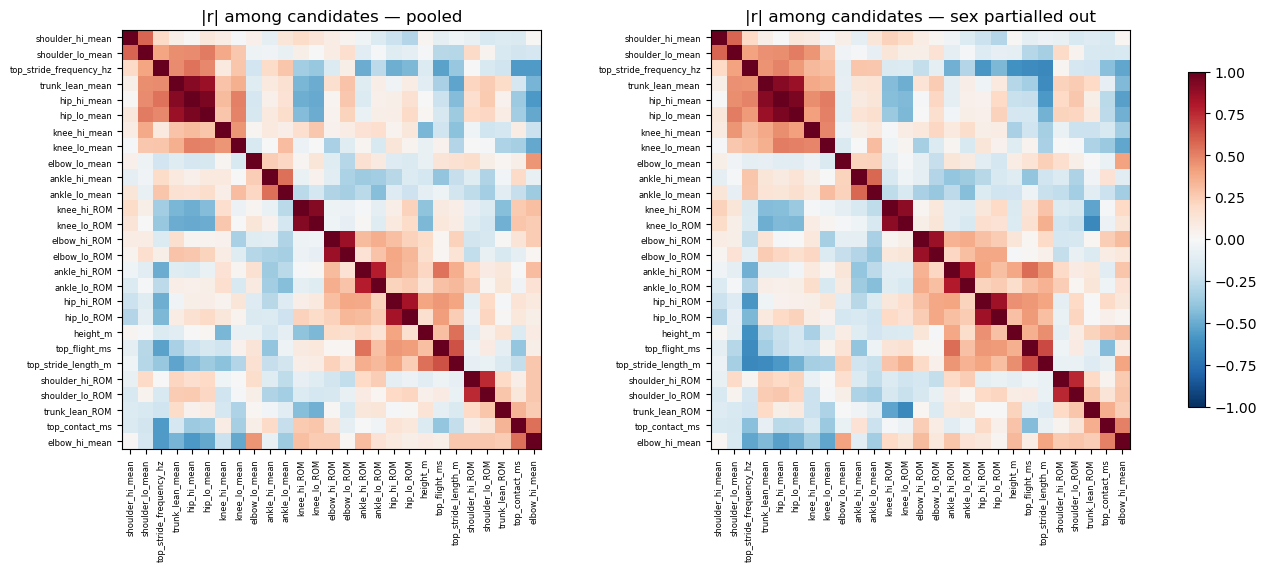

In [4]:
cols = GAIT + ANGLES
Z = F[cols]
resid = lambda v: v - np.polyval(np.polyfit(male, v, 1), male)
Zp = Z.apply(resid)
# linkage clusters ROWS, and the rows here must be the FEATURES - hence the transpose
order = [cols[i] for i in leaves_list(linkage(((Z - Z.mean()) / Z.std()).T.to_numpy(), method="average"))]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), constrained_layout=True)
for ax, (data, title) in zip(axes, [(Z, "pooled"), (Zp, "sex partialled out")]):
    cc = data[order].corr()
    im = ax.imshow(cc, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=f"|r| among candidates — {title}")
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=6)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.8)

pairs = (Z.corr().abs().where(np.triu(np.ones((len(cols),) * 2, bool), 1))
         .stack().sort_values(ascending=False))
print("strongest pooled pairs (|r| > 0.8):")
print(pairs[pairs > 0.8].round(2).to_string())

## 4 · What collinearity does to real coefficients

Model 1 (sex + contact time) refit 30 times, leaving one athlete out each time: if the inputs were collinear,
these coefficients would swing fold to fold. Then the same for a deliberately collinear model (sex + stride
length + stride frequency — two components of the target and of each other).

In [5]:
def fold_coefs(X):
    return np.array([LinearRegression().fit(np.delete(X, i, 0), np.delete(y, i)).coef_ for i in range(len(y))])

stable = fold_coefs(np.column_stack([male, F.top_contact_ms]))
wobbly = fold_coefs(np.column_stack([male, F.top_stride_length_m, F.top_stride_frequency_hz]))
report = pd.DataFrame({
    "model": ["sex + contact (model 1)"] * 2 + ["sex + stride len + stride freq"] * 3,
    "coefficient": ["sex", "contact_ms", "sex", "stride_len", "stride_freq"],
    "mean": np.r_[stable.mean(0), wobbly.mean(0)],
    "sd_across_folds": np.r_[stable.std(0), wobbly.std(0)],
})
report["cv_%"] = (100 * report.sd_across_folds / report["mean"].abs()).round(1)
report.round(3)

,model,coefficient,mean,sd_across_folds,cv_%
0,sex + contact (model 1),sex,0.902,0.022,2.4
1,sex + contact (model 1),contact_ms,-0.015,0.001,6.6
2,sex + stride len + stride freq,sex,0.414,0.059,14.1
3,sex + stride len + stride freq,stride_len,1.390,0.120,8.6
4,sex + stride len + stride freq,stride_freq,3.031,0.114,3.8


## 5 · What this says for the pipeline

* **The as-modelled set is clean** (all VIF < 5): contact time's coefficient is trustworthy, which is why
  model 1's folds barely move it.
* **Stride frequency is the worst offender** — not because of biology but because it is 1/(contact + flight)
  by construction, and those two are already in the pool. Any model containing all three is fitting an identity.
  It stays out of predictive models (and the physics identity in 05 is the honest place it lives); stride length
  on its own is actually well-behaved, but it is a component of the target, so it stays out too.
* **The 22 angle scalars contain large near-duplicate blocks** (hi/lo ROM pairs, mean-angle pairs): whole-body
  information at n = 30 supports ~2 effective directions — the same answer the nested tuning gave (k = 2 modes).
* **Never run or report full-set VIF at n = 30** — section 2 is the demonstration of why.

In [6]:
assert vif_small.max() < 5, vif_small                    # the as-modelled set is clean
assert vif_ext["top_stride_frequency_hz"] > 10                                  # the 1/(tc+tf) identity explodes it
assert vif_ext["top_stride_length_m"] < 5                                        # ...and stride length alone is fine
assert vif_full.max() > 50                      # the degeneracy demo actually demonstrates it
assert report.loc[report.coefficient == "contact_ms", "cv_%"].iloc[0] < 20
print("collinearity checks passed")

collinearity checks passed
